# Tổng hợp kết quả HE-CFE

Notebook này đọc các bảng tổng hợp trong `ket_qua_tong_hop/`, không chạy lại thí nghiệm. Phạm vi: ECG, Heart+, MIMIC-IV, Adult. Mỗi dataset gồm 200 factual outer, K = 10, margin logit 0.10, search seed 11 trừ mục seed. Yield bão hòa nên phải đọc cùng robust, proximity, sparsity, diversity.

In [1]:
import pandas as pd, matplotlib.pyplot as plt, numpy as np
from IPython.display import display
pd.set_option('display.max_rows',100); pd.set_option('display.max_columns',30); pd.set_option('display.float_format',lambda v:f'{v:.3f}')
D='ket_qua_tong_hop/'
plt.rcParams.update({'figure.dpi':130,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'axes.grid.axis':'y','grid.color':'#e6e5e0','axes.axisbelow':True,'font.size':10})
C1,C2='#2a78d6','#eb6834'
def bars(ax,labels,a,b,la,lb,ylabel,fmt):
    x=np.arange(len(labels)); w=.36
    for off,v,c,l in [(-w/2,a,C1,la),(w/2,b,C2,lb)]:
        r=ax.bar(x+off,v,w-.03,color=c,label=l); ax.bar_label(r,fmt=fmt,padding=2,fontsize=9)
    ax.set_xticks(x,labels); ax.set_ylabel(ylabel); ax.legend(frameon=False,ncol=2,loc='upper center',bbox_to_anchor=(.5,1.14))

## 1. GA-div tìm kiếm mã hóa đầu cuối (E2)

Các chế độ `encrypted_*` là mã hóa, `plaintext_*` là bản rõ đối chứng. `heartplus_do_nhay` là profile N8192, chỉ để đo độ nhạy và không đạt yêu cầu trùng bản rõ.

In [2]:
e2=pd.read_csv(D+'e2_ga_div_ma_hoa.csv'); display(e2)

,dataset,cau_hinh,mode,factuals,valid_cfe_yield_at_k,robust_completeness_at_k,proximity,sparsity,diversity,wall_clock_search_seconds,server_observed_rounds
0,ecg,P64 R4 N16384,encrypted_early_stop,200,1.000,0.809,0.088,0.179,0.106,109.706,1.290
1,ecg,P64 R4 N16384,encrypted_fixed_r,200,1.000,0.859,0.085,0.273,0.101,340.101,4.000
2,ecg,P64 R4 N16384,plaintext_early_stop,200,1.000,0.809,0.088,0.179,0.106,0.079,1.290
3,ecg,P64 R4 N16384,plaintext_fixed_r,200,1.000,0.859,0.085,0.273,0.101,0.329,4.000
4,heartplus,P64 R16 N16384,encrypted_early_stop,200,0.762,0.738,0.108,0.470,0.078,518.843,8.135
5,heartplus,P64 R16 N16384,encrypted_fixed_r,200,0.762,0.721,0.091,0.552,0.064,1018.299,16.000
6,heartplus,P64 R16 N16384,plaintext_early_stop,200,0.762,0.738,0.108,0.470,0.078,0.102,8.135
7,heartplus,P64 R16 N16384,plaintext_fixed_r,200,0.762,0.721,0.091,0.552,0.064,0.255,16.000
8,mimic,P128 R8 N16384,encrypted_early_stop,200,0.990,0.772,0.094,0.165,0.108,206.734,2.565
9,mimic,P128 R8 N16384,encrypted_fixed_r,200,0.990,0.850,0.094,0.237,0.107,644.545,8.000


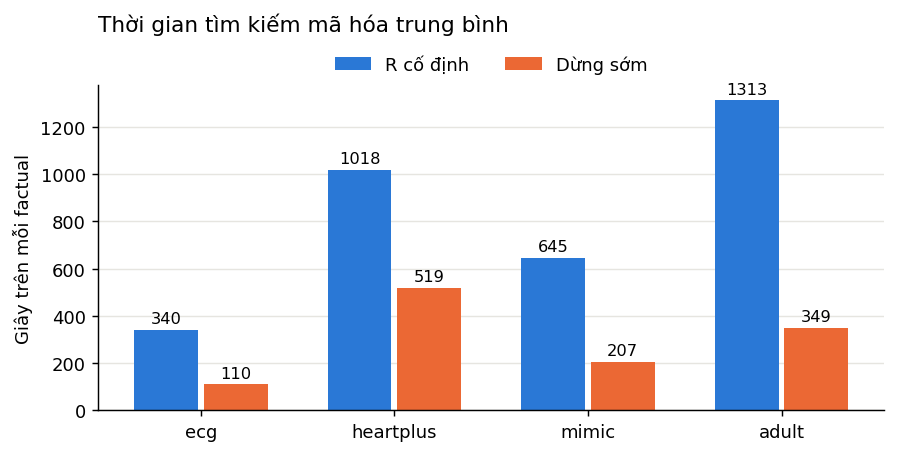

In [3]:
m=e2[~e2.dataset.str.contains('do_nhay')]
f=m[m['mode']=='encrypted_fixed_r'].set_index('dataset'); s=m[m['mode']=='encrypted_early_stop'].set_index('dataset').loc[f.index]
fig,ax=plt.subplots(figsize=(7,3.6)); bars(ax,list(f.index),f.wall_clock_search_seconds,s.wall_clock_search_seconds,'R cố định','Dừng sớm','Giây trên mỗi factual','%.0f')
ax.set_title('Thời gian tìm kiếm mã hóa trung bình',pad=30,loc='left'); plt.tight_layout(); plt.show()

## 2. Ablation (E1, E1b)

In [4]:
display(pd.read_csv(D+'e1_ablation.csv').sort_values(['dataset','method']))

,method,dataset,P,R,valid_cfe_yield_at_k,robust_completeness_at_k,proximity,sparsity,diversity,plausibility_inlier_rate,redundancy
33,gaussian_ga,adult,64,16,0.305,0.164,0.029,0.947,0.031,0.402,0.225
34,gaussian_ga__no_mmr,adult,64,16,0.305,0.163,0.029,0.947,0.031,0.402,0.224
35,gaussian_ga__no_projection,adult,64,16,0.000,0.000,NaN,NaN,NaN,NaN,NaN
36,gaussian_ga_div,adult,64,16,0.996,0.672,0.054,0.914,0.072,0.458,0.963
37,gaussian_ga_div__no_archive_parents,adult,64,16,0.989,0.693,0.055,0.912,0.073,0.451,0.975
38,gaussian_ga_div__no_crowding,adult,64,16,0.993,0.618,0.051,0.918,0.067,0.480,0.895
39,gaussian_ga_div__no_dedup,adult,64,16,1.000,0.684,0.056,0.912,0.073,0.450,0.880
40,gaussian_ga_div__no_immigrants,adult,64,16,0.994,0.655,0.056,0.911,0.072,0.445,0.932
41,gaussian_ga_div__no_mmr,adult,64,16,0.996,0.672,0.054,0.914,0.071,0.458,0.969
42,gaussian_ga_div__no_projection,adult,64,16,0.000,0.000,NaN,NaN,NaN,NaN,NaN


## 3. So với baseline (E3)

NICE và GeCo là bản cài lại. Official DiCE không phải equal-compute. Với GeCo đây là đánh đổi: GA-div bền và đa dạng hơn, GeCo gần và thưa hơn.

In [5]:
display(pd.read_csv(D+'e3_baseline.csv').sort_values(['dataset','method']))
g=pd.read_csv(D+'ga_div_vs_geco.csv'); display(g)

,method,dataset,valid_cfe_yield_at_k,robust_completeness_at_k,proximity,sparsity,diversity,count_diversity,redundancy,plausibility_inlier_rate,runtime_seconds,oracle_evaluations
0,geco,adult,1.000,0.359,0.049,0.928,0.057,0.084,0.571,0.602,0.826,2429.000
1,nice_proximity,adult,0.099,0.028,0.038,0.938,0.000,NaN,0.066,0.822,0.348,20004.250
2,nice_sparsity,adult,0.099,0.028,0.038,0.940,0.000,NaN,0.005,0.822,0.343,20004.170
9,official_dice_genetic,adult,0.666,0.314,0.102,0.856,0.104,0.150,2.669,0.450,8.083,NaN
10,official_dice_random,adult,0.364,0.144,0.045,0.937,0.059,0.094,0.457,0.661,0.755,NaN
3,geco,ecg,1.000,0.350,0.027,0.870,0.028,0.119,1.187,0.107,1.890,4500.000
4,nice_proximity,ecg,0.100,0.044,0.030,0.791,0.000,NaN,1.490,0.220,0.492,20054.855
5,nice_sparsity,ecg,0.100,0.035,0.028,0.802,0.000,NaN,1.225,0.195,0.436,20040.690
6,geco,heartplus,0.733,0.691,0.082,0.655,0.044,0.241,0.812,0.598,0.725,7160.000
7,nice_proximity,heartplus,0.079,0.067,0.067,0.716,0.000,NaN,0.229,0.592,0.104,20006.905


,dataset,metric,n,ga_div,geco,diff,ci_lo,ci_hi,p,p_holm
0,ecg,valid_cfe_yield_at_k,200,1.000,1.000,0.000,0.000,0.000,1.000,1.000
1,ecg,robust_completeness_at_k,200,0.859,0.350,0.509,0.476,0.543,0.000,0.000
2,ecg,proximity,200,0.085,0.027,0.058,0.057,0.059,0.000,0.000
3,ecg,sparsity,200,0.273,0.870,-0.597,-0.603,-0.590,0.000,0.000
4,ecg,plausibility_inlier_rate,200,0.019,0.107,-0.087,-0.119,-0.058,0.000,0.000
5,heartplus,valid_cfe_yield_at_k,200,0.762,0.733,0.029,0.011,0.050,0.002,0.011
6,heartplus,robust_completeness_at_k,200,0.721,0.691,0.030,0.009,0.054,0.014,0.071
7,heartplus,proximity,154,0.087,0.081,0.006,0.003,0.008,0.000,0.000
8,heartplus,sparsity,154,0.563,0.657,-0.095,-0.106,-0.082,0.000,0.000
9,heartplus,plausibility_inlier_rate,154,0.428,0.602,-0.173,-0.209,-0.136,0.000,0.000


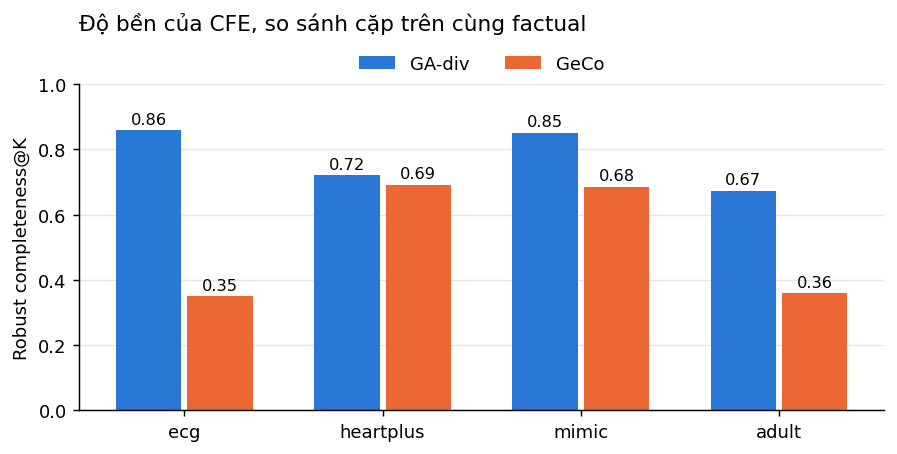

In [6]:
r=g[g.metric=='robust_completeness_at_k'].set_index('dataset')
fig,ax=plt.subplots(figsize=(7,3.6)); bars(ax,list(r.index),r.ga_div,r.geco,'GA-div','GeCo','Robust completeness@K','%.2f')
ax.set_ylim(0,1); ax.set_title('Độ bền của CFE, so sánh cặp trên cùng factual',pad=30,loc='left'); plt.tight_layout(); plt.show()

## 4. Cohort xác nhận

GA-div là biến thể hậu kiểm nên được kiểm tra lại trên cohort không giao với outer.

In [7]:
display(pd.read_csv(D+'cohort_xac_nhan.csv')); display(pd.read_csv(D+'cohort_xac_nhan_kiem_dinh.csv'))

,dataset,population,rounds,method,metric,n,mean,ci95_low,ci95_high
0,ecg,64,4,gaussian_ga,valid_cfe_yield_at_k,200,1.000,1.000,1.000
1,ecg,64,4,gaussian_ga,robust_completeness_at_k,200,0.844,0.828,0.860
2,ecg,64,4,gaussian_ga,proximity,200,0.076,0.075,0.077
3,ecg,64,4,gaussian_ga,sparsity,200,0.314,0.307,0.322
4,ecg,64,4,gaussian_ga,diversity,200,0.088,0.086,0.089
5,ecg,64,4,gaussian_ga,plausibility_inlier_rate,200,0.035,0.021,0.050
6,ecg,64,4,gaussian_ga_div,valid_cfe_yield_at_k,200,1.000,1.000,1.000
7,ecg,64,4,gaussian_ga_div,robust_completeness_at_k,200,0.854,0.839,0.869
8,ecg,64,4,gaussian_ga_div,proximity,200,0.082,0.081,0.083
9,ecg,64,4,gaussian_ga_div,sparsity,200,0.278,0.271,0.285


,dataset,a,b,metric,paired_n,mean_diff_a_minus_b,ci95_low,ci95_high,wilcoxon_p
0,ecg,gaussian_ga_div,gaussian_ga,valid_cfe_yield_at_k,200,0.000,0.000,0.000,1.000
1,ecg,gaussian_ga_div,gaussian_ga,robust_completeness_at_k,200,0.010,-0.010,0.030,0.280
2,ecg,gaussian_ga_div,gaussian_ga,proximity,200,0.006,0.005,0.007,0.000
3,ecg,gaussian_ga_div,gaussian_ga,sparsity,200,-0.036,-0.043,-0.030,0.000
4,ecg,gaussian_ga_div,gaussian_ga,diversity,200,0.010,0.009,0.012,0.000
5,ecg,gaussian_ga_div,gaussian_ga,plausibility_inlier_rate,200,-0.003,-0.012,0.006,0.676
6,ecg,gaussian_ga_div,gaussian_only,valid_cfe_yield_at_k,200,0.000,0.000,0.000,1.000
7,ecg,gaussian_ga_div,gaussian_only,robust_completeness_at_k,200,0.037,0.019,0.055,0.000
8,ecg,gaussian_ga_div,gaussian_only,proximity,200,-0.007,-0.008,-0.006,0.000
9,ecg,gaussian_ga_div,gaussian_only,sparsity,200,0.064,0.059,0.069,0.000


## 5. Ổn định theo search seed (E5) và rút gọn CFE

In [8]:
display(pd.read_csv(D+'e5_search_seed.csv')); display(pd.read_csv(D+'rut_gon_cfe.csv'))

,dataset,method,seed,valid_cfe_yield_at_k,robust_completeness_at_k,proximity,sparsity,diversity
0,ecg,gaussian_ga,11,1.000,0.844,0.079,0.307,0.089
1,ecg,gaussian_ga,22,1.000,0.833,0.079,0.309,0.091
2,ecg,gaussian_ga,33,1.000,0.856,0.079,0.307,0.089
3,ecg,gaussian_ga_div,11,1.000,0.859,0.085,0.273,0.101
4,ecg,gaussian_ga_div,22,1.000,0.845,0.084,0.279,0.100
5,ecg,gaussian_ga_div,33,1.000,0.847,0.084,0.272,0.100
6,ecg,gaussian_only,11,1.000,0.801,0.093,0.204,0.119
7,ecg,gaussian_only,22,1.000,0.814,0.092,0.207,0.119
8,ecg,gaussian_only,33,1.000,0.810,0.093,0.206,0.120
9,heartplus,gaussian_ga,11,0.379,0.345,0.051,0.690,0.029


,method,dataset,valid_cfe_yield_at_k,robust_completeness_at_k,proximity,sparsity,count_diversity,redundancy,plausibility_inlier_rate
0,gaussian_ga,ecg,1.000,0.877,0.067,0.539,0.568,7.152,0.034
1,gaussian_only,ecg,1.000,0.801,0.094,0.213,0.853,12.285,0.016
2,gaussian_ga_div,ecg,1.000,0.893,0.083,0.440,0.686,8.958,0.012
3,gaussian_ga__reduce,ecg,1.000,0.574,0.040,0.746,0.374,2.758,0.072
4,gaussian_ga_div__reduce,ecg,1.000,0.593,0.045,0.679,0.461,3.874,0.068
5,gaussian_only__reduce,ecg,1.000,0.672,0.054,0.497,0.631,6.988,0.054
6,gaussian_ga,heartplus,0.378,0.345,0.051,0.690,0.268,0.998,0.607
7,gaussian_only,heartplus,0.552,0.522,0.074,0.575,0.384,1.775,0.451
8,gaussian_ga_div,heartplus,0.762,0.721,0.091,0.552,0.371,1.579,0.419
9,gaussian_ga__reduce,heartplus,0.378,0.343,0.049,0.710,0.250,0.782,0.615


## 6. Rò rỉ còn lại sau mã hóa (E6)

HE không bảo vệ mô hình trước client.

In [9]:
display(pd.read_csv(D+'e6_ro_ri_so_vong.csv')); display(pd.read_csv(D+'e6_trich_xuat_mo_hinh.csv').head(36))

,run,mode,factuals,distinct_round_counts,mean_rounds,spearman_rho_rounds_vs_abs_logit,mutual_information_nats
0,ecg,encrypted_early_stop,200,3,1.300,0.638,0.250
1,ecg,encrypted_fixed_r,200,1,4.000,NaN,0.000
2,heartplus,encrypted_early_stop,200,16,10.890,0.726,0.507
3,heartplus,encrypted_fixed_r,200,1,16.000,NaN,0.000
4,mimic,encrypted_early_stop,200,8,2.715,0.835,0.541
5,mimic,encrypted_fixed_r,200,1,8.000,NaN,0.000
6,heartplus_ga_div,encrypted_early_stop,200,14,8.085,0.893,0.722
7,heartplus_ga_div,encrypted_fixed_r,200,1,16.000,NaN,0.000
8,adult_ga_div,encrypted_early_stop,200,14,4.290,0.808,0.600
9,adult_ga_div,encrypted_fixed_r,200,1,16.000,NaN,0.000


,dataset,factuals,queries,feedback,surrogate,test_label_agreement,majority_baseline
0,adult,1,1024,logit,linear,0.774,0.712
1,adult,1,1024,logit,mlp,0.793,0.712
2,adult,1,1024,quantized,linear,0.770,0.712
3,adult,1,1024,quantized,mlp,0.775,0.712
4,adult,1,1024,label,logistic,0.844,0.712
5,adult,1,1024,label,mlp,0.789,0.712
6,adult,5,5120,logit,linear,0.919,0.712
7,adult,5,5120,logit,mlp,0.853,0.712
8,adult,5,5120,quantized,linear,0.920,0.712
9,adult,5,5120,quantized,mlp,0.855,0.712


## 7. Số batch mã hóa tuần tự (E10) và mốc LOF Adult

In [10]:
display(pd.read_csv(D+'e10_so_batch.csv')); display(pd.read_csv(D+'lof_adult.csv'))

,dataset,method,sequential_batches_mean,he_seconds_per_round,he_seconds_estimate
0,ecg,gaussian_ga_div_early_stop,1.290,85.025,109.682
1,ecg,gaussian_ga_div_fixed_r,4.000,85.025,340.101
2,ecg,gaussian_ga_div_milestone,2.020,85.025,171.751
3,ecg,geco,21.700,85.025,1845.046
4,heartplus,gaussian_ga_div_early_stop,8.135,63.644,517.741
5,heartplus,gaussian_ga_div_fixed_r,16.000,63.644,1018.299
6,heartplus,gaussian_ga_div_milestone,9.230,63.644,587.431
7,heartplus,geco,35.900,63.644,2284.809
8,mimic,gaussian_ga_div_early_stop,2.565,80.568,206.657
9,mimic,gaussian_ga_div_fixed_r,8.000,80.568,644.545


,dataset,item,inlier_rate
0,adult,real_test_noise_0,0.890
1,adult,real_test_noise_0.01,0.887
2,adult,real_test_noise_0.02,0.877
3,adult,real_test_noise_0.05,0.802
4,adult,real_test_noise_0.12,0.470
5,adult,cfe_refit_lof,0.461
6,adult,cfe_kaggle_reported,0.459
